In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize, ListedColormap

fronts = xr.load_dataset(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/62985.nc"
)

seaice = xr.load_dataset(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/sic_climatology_stats_sh_1991-2020.nc"
)
seaice_mmean = seaice.mmean


# ============================================================
# 1) LOAD ONLY PREDICTIONS
# ============================================================

# ---------- SOCAT ----------
predictions_socat = pd.read_csv(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/"
    "pco2_prediction_matrix_SOCAT_only_MCensemble.csv"
)

predictions_socat["month_center"] = pd.to_datetime(predictions_socat["month_center"])
predictions_socat = predictions_socat[
    ~((predictions_socat["month_center"].dt.year == 2023) &
      (predictions_socat["month_center"].dt.month == 2))
]

# ---------- FLOATS ----------
predictions_floats = pd.read_csv(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/"
    "pco2_prediction_matrix_FLOATS_only_MCensemble.csv"
)

predictions_floats["month_center"] = pd.to_datetime(predictions_floats["month_center"])
predictions_floats = predictions_floats[
    ~((predictions_floats["month_center"].dt.year == 2023) &
      (predictions_floats["month_center"].dt.month == 2))
]


# ============================================================
# 2) ADD SEASON LABELS
# ============================================================

def assign_season(month):
    if month in [12, 1, 2]:
        return "DJF"
    elif month in [3, 4, 5]:
        return "MAM"
    elif month in [6, 7, 8]:
        return "JJA"
    else:
        return "SON"

for df in [predictions_socat, predictions_floats]:
    df["month"] = df["month_center"].dt.month
    df["season"] = df["month"].apply(assign_season)


# ============================================================
# 3) SEASONAL MEAN UNCERTAINTY PER GRID CELL AUTO-DETECT
# ============================================================

def seasonal_mean_uncertainty(df):
    """
    Returns mean ensemble uncertainty per season per grid cell
    Automatically detects:
      - latitude / longitude
      - OR lat_center / lon_center
    """

    if {"latitude", "longitude"}.issubset(df.columns):
        lat_col, lon_col = "latitude", "longitude"
    elif {"lat_center", "lon_center"}.issubset(df.columns):
        lat_col, lon_col = "lat_center", "lon_center"
    else:
        raise KeyError("No valid latitude/longitude columns found in dataframe.")

    out = (
        df
        .groupby(["season", lat_col, lon_col])["ensemble_pco2_std"]
        .mean()
        .reset_index()
        .rename(columns={lat_col: "latitude", lon_col: "longitude"})
    )

    return out


seasonal_socat  = seasonal_mean_uncertainty(predictions_socat)
seasonal_floats = seasonal_mean_uncertainty(predictions_floats)


/tmp/ipykernel_3424978/3866763493.py:290: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.10, 1, 0.96])


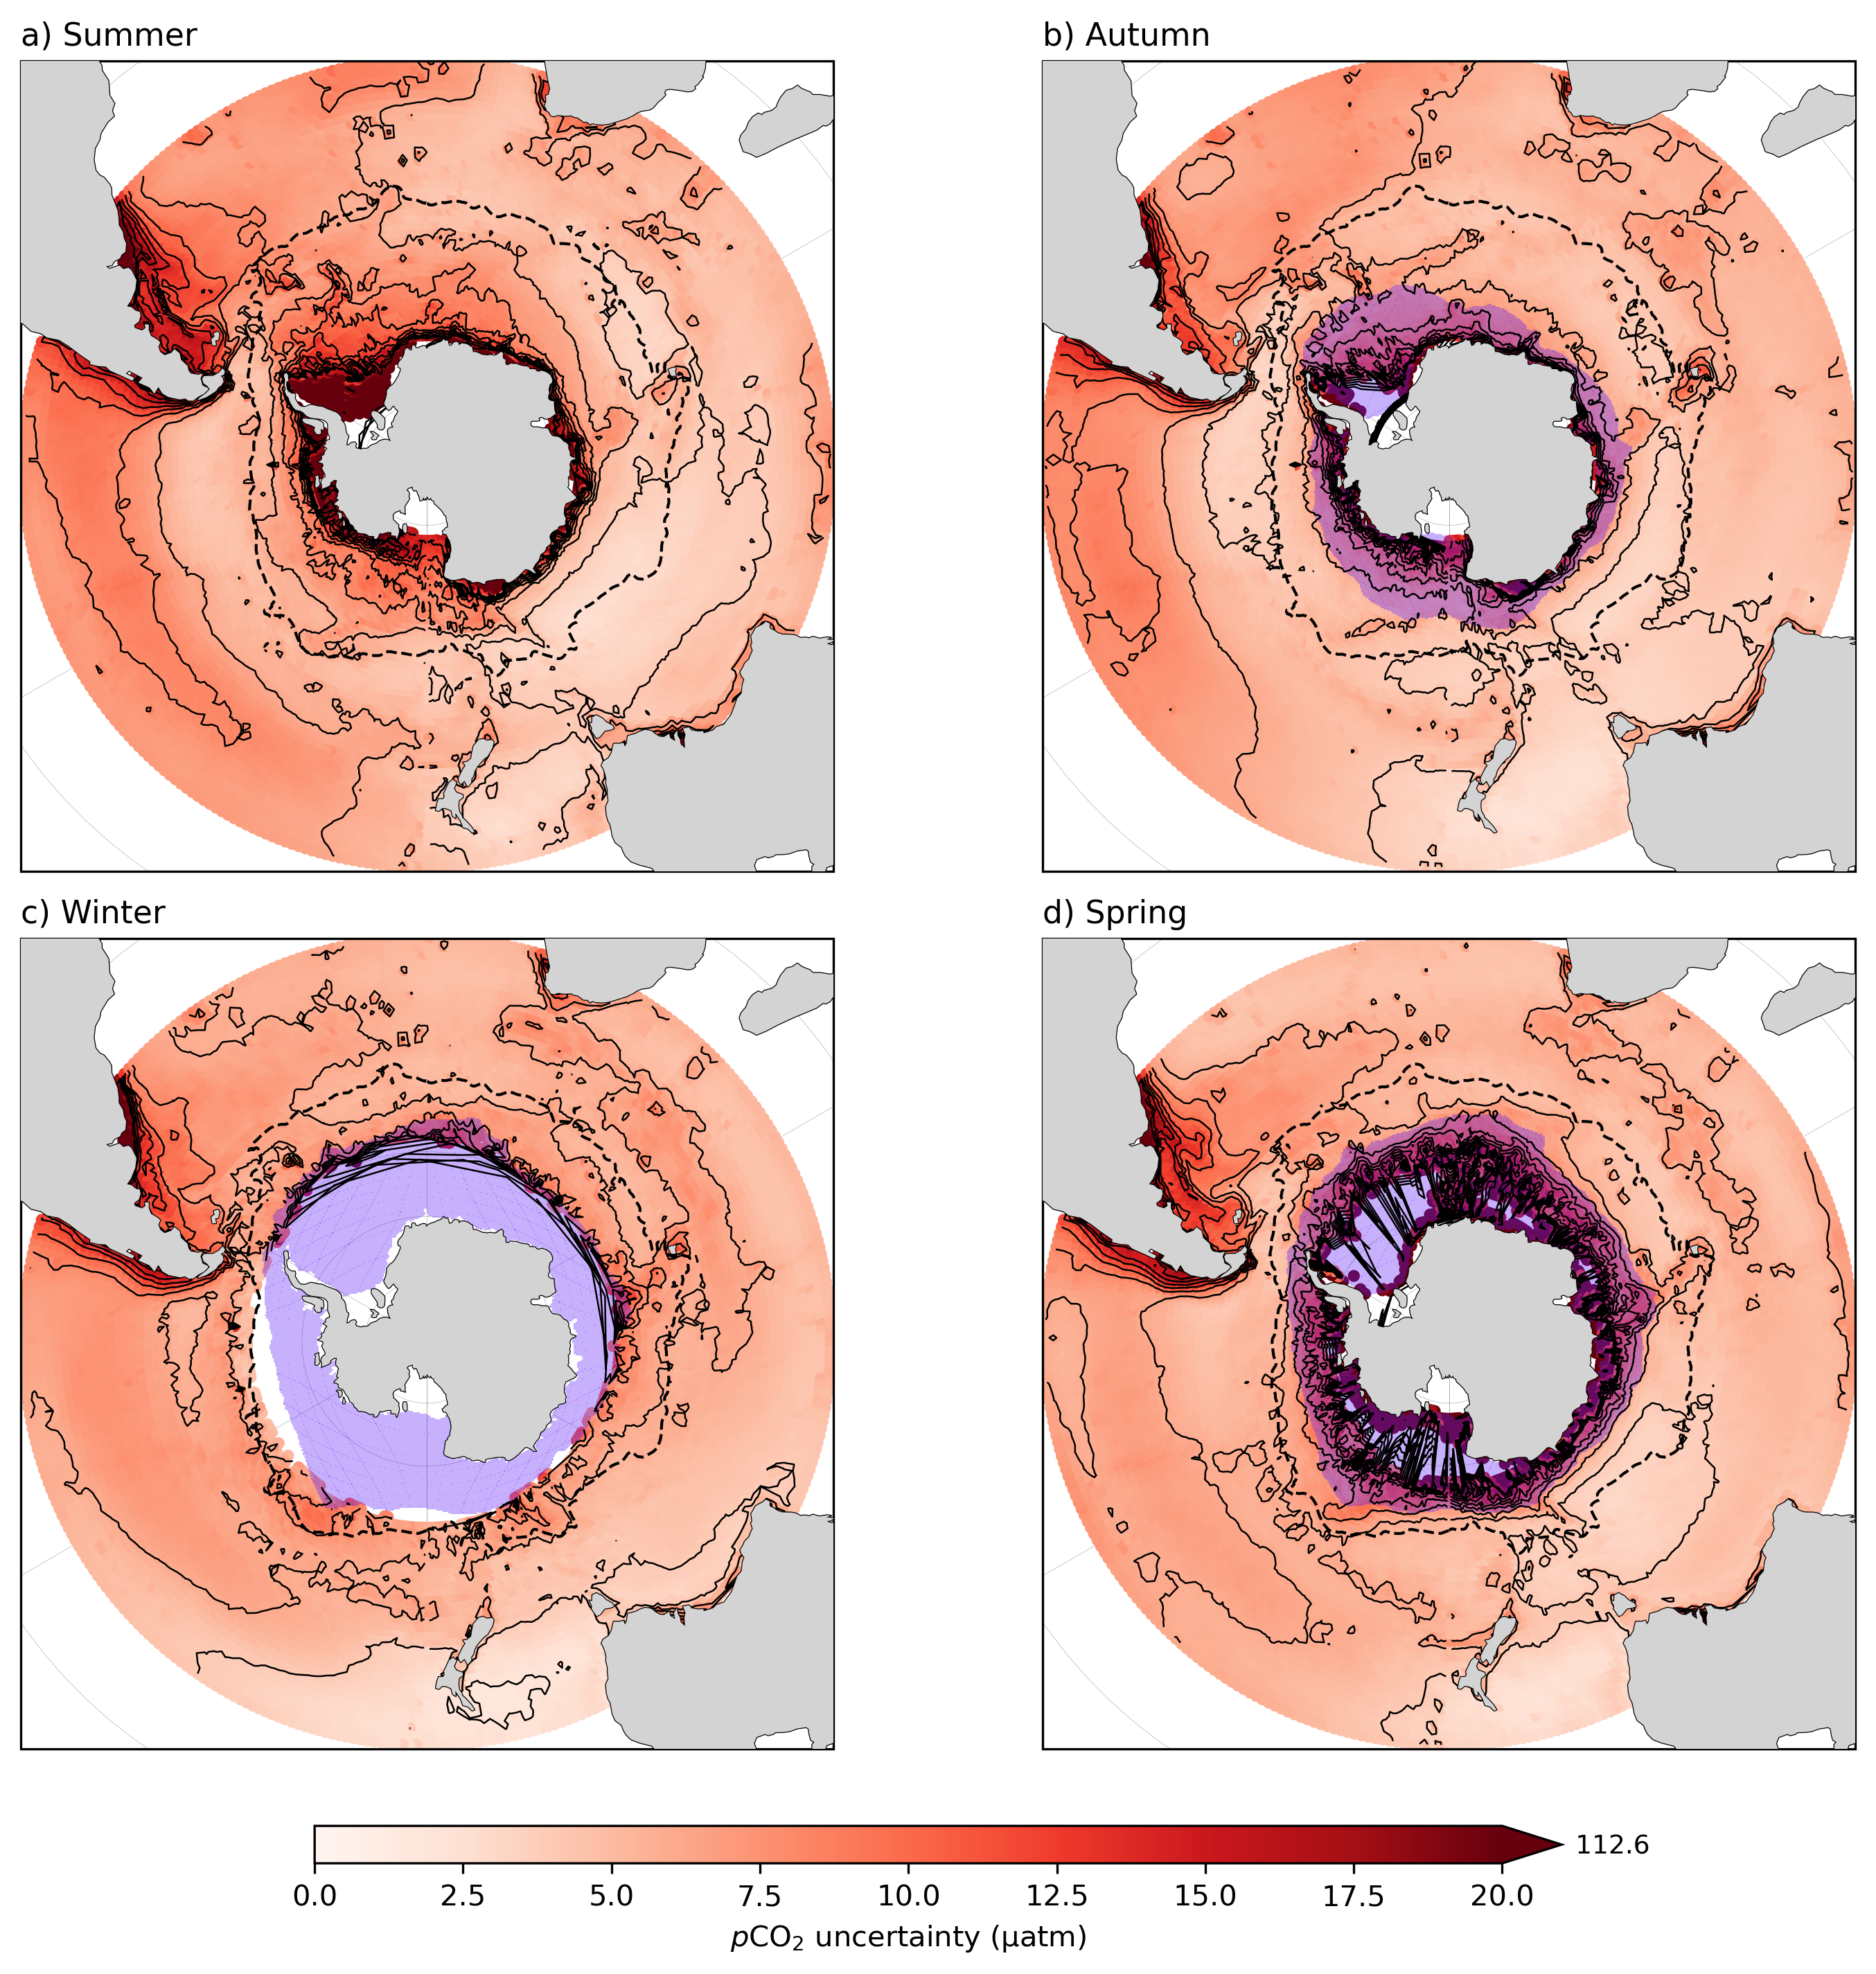

In [2]:
# ============================================================
# SOUTHERN OCEAN MAP PLOTTING FUNCTION (4 SEASONS)
# - Scatter uncertainty + contour lines (interval configurable)
# - Optional sea-ice seasonal max mask
# - Optional Polar Front overlay
# - Continents (LAND) drawn ON TOP of everything else
# - Full manual control of colorbar geometry
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize, ListedColormap


# ============================================================
# HELPERS: Orsi fronts plotting (handles 0..360 lon, NaNs, dateline jumps)
# ============================================================

def lon360_to_lon180(lon):
    lon = np.asarray(lon)
    return ((lon + 180) % 360) - 180

def plot_front_line(ax, lon, lat, *, jump_deg=20, **plot_kwargs):
    lon = np.asarray(lon).astype(float)
    lat = np.asarray(lat).astype(float)

    m = np.isfinite(lon) & np.isfinite(lat)
    lon = lon[m]
    lat = lat[m]

    lon = lon360_to_lon180(lon)
    if lon.size < 2:
        return

    dlon = np.abs(np.diff(lon))
    breaks = np.where(dlon > jump_deg)[0] + 1
    idxs = np.concatenate(([0], breaks, [lon.size]))

    for a, b in zip(idxs[:-1], idxs[1:]):
        if b - a < 2:
            continue
        ax.plot(
            lon[a:b],
            lat[a:b],
            transform=ccrs.PlateCarree(),
            **plot_kwargs
        )


# ============================================================
# HELPERS: Sea-ice seasonal MAX mask (ice-only fill, no contours)
# ============================================================

SEASON_TO_MONTHS = {
    "DJF": [12, 1, 2],
    "MAM": [3, 4, 5],
    "JJA": [6, 7, 8],
    "SON": [9, 10, 11],
}

def seasonal_max_from_monthly_clim(seaice_mmean, season):
    months = SEASON_TO_MONTHS[season]
    return seaice_mmean.sel(month=months).max("month", skipna=True)

ICE_CMAP = ListedColormap(["#601ef9"])  # soft purple

def plot_ice_mask_seasonal_max_iceonly(
    ax, seaice_mmean, season, *, threshold_percent=15.0, alpha=0.35, zorder=5
):
    sic_max = seasonal_max_from_monthly_clim(seaice_mmean, season)

    lon2d = sic_max["lon"].values
    lat2d = sic_max["lat"].values

    ice = sic_max.values >= threshold_percent
    ice_only = np.where(ice, 1.0, np.nan)

    ax.pcolormesh(
        lon2d,
        lat2d,
        ice_only,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=ICE_CMAP,
        vmin=0,
        vmax=1,
        alpha=alpha,
        zorder=zorder
    )


# ============================================================
# MAIN PLOTTING FUNCTION
# ============================================================

def plot_seasonal_uncertainty_maps(
    df_seasonal,
    title_prefix,
    output_path,
    contour_step=5,
    contour_min=None,
    contour_max=None,
    contour_color="k",
    contour_lw=0.6,
    contour_label=False,
    land_color="lightgray",
    seaice_mmean=None,
    ice_threshold_percent=15.0,
    ice_alpha=0.35,
    fronts=None,
    point_size=10
):
    """
    df_seasonal must contain columns:
      - longitude, latitude, ensemble_pco2_std, season

    Optional:
      - seaice_mmean: monthly sea-ice climatology with dims/coords including month, lon, lat
      - fronts: dataframe/dataset containing LonPF and LatPF
    """

    # Southern Hemisphere season order + labels
    season_order = ["DJF", "MAM", "JJA", "SON"]
    season_labels = {
        "DJF": "Summer",
        "MAM": "Autumn",
        "JJA": "Winter",
        "SON": "Spring",
    }

    panel_letters = ["a", "b", "c", "d"]

    # ----------------------------------------
    # COLOR SCALING
    # ----------------------------------------
    vmin = 0.0
    vmax = 20.0
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = "Reds"

    true_max = df_seasonal["ensemble_pco2_std"].max()

    # ----------------------------------------
    # CONTOUR LEVELS
    # ----------------------------------------
    if contour_step is None or contour_step <= 0:
        raise ValueError("contour_step must be a positive number (e.g., 5).")

    cmin = vmin if contour_min is None else float(contour_min)
    cmax = vmax if contour_max is None else float(contour_max)
    contour_levels = np.arange(cmin, cmax + 0.1, float(contour_step))

    # ----------------------------------------
    # FIGURE
    # ----------------------------------------
    fig, axs = plt.subplots(
        2, 2,
        figsize=(10, 10),
        dpi=300,
        subplot_kw={"projection": ccrs.SouthPolarStereo()}
    )
    axs = axs.flatten()

    # Land feature to draw last
    land_feature = cfeature.NaturalEarthFeature(
        "physical",
        "land",
        "110m",
        edgecolor="none",
        facecolor=land_color
    )

    for i, (ax, season) in enumerate(zip(axs, season_order)):

        ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

        # Bottom layer
        ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5)

        df_s = df_seasonal[df_seasonal["season"] == season].copy()

        # Scatter plot
        sc = ax.scatter(
            df_s["longitude"].values,
            df_s["latitude"].values,
            c=df_s["ensemble_pco2_std"].values,
            s=point_size,
            cmap=cmap,
            norm=norm,
            transform=ccrs.PlateCarree(),
            zorder=2
        )

        # Sea-ice mask for autumn, winter, and spring
        if seaice_mmean is not None and season in ["MAM", "JJA", "SON"]:
            plot_ice_mask_seasonal_max_iceonly(
                ax,
                seaice_mmean,
                season,
                threshold_percent=ice_threshold_percent,
                alpha=ice_alpha,
                zorder=3
            )

        # Contours
        mask = (
            np.isfinite(df_s["longitude"].values) &
            np.isfinite(df_s["latitude"].values) &
            np.isfinite(df_s["ensemble_pco2_std"].values)
        )
        dff = df_s.loc[mask]

        if len(dff) >= 10:
            ct = ax.tricontour(
                dff["longitude"].values,
                dff["latitude"].values,
                dff["ensemble_pco2_std"].values,
                levels=contour_levels,
                colors=contour_color,
                linewidths=contour_lw,
                transform=ccrs.PlateCarree(),
                zorder=4
            )
            if contour_label:
                ax.clabel(ct, fmt="%g", fontsize=7, inline=True)

        # Polar Front
        if fronts is not None:
            plot_front_line(
                ax,
                fronts["LonPF"].values,
                fronts["LatPF"].values,
                jump_deg=20,
                linewidth=1.0,
                linestyle="--",
                color="k",
                zorder=6
            )

        # Coastlines
        ax.coastlines(resolution="110m", linewidth=0.6, zorder=7)

        # LAND / CONTINENTS ON TOP
        ax.add_feature(land_feature, zorder=10)

        # Panel label
        ax.text(
            0,
            1.05,
            f"{panel_letters[i]}) {season_labels[season]}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=11
        )

    # ============================================================
    # COLORBAR
    # ============================================================
    cax = fig.add_axes([
        0.20,   # left
        0.06,   # bottom
        0.60,   # width
        0.018   # height
    ])

    cbar = fig.colorbar(
        sc,
        cax=cax,
        orientation="horizontal",
        extend="max"
    )

    cbar.set_label(r"$p$CO$_2$ uncertainty (µatm)")

    # Annotate true max next to arrow
    cbar.ax.text(
        1.02, 0.45,
        f"      {true_max:.1f}",
        transform=cbar.ax.transAxes,
        va="center",
        ha="left",
        fontsize=9
    )

    # Layout + save
    # fig.suptitle(f"{title_prefix} — Mean Seasonal MC Uncertainty", fontsize=14)
    plt.tight_layout(rect=[0, 0.10, 1, 0.96])
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


# ============================================================
# PLOT SOCAT SEASONAL UNCERTAINTY
# ============================================================

plot_seasonal_uncertainty_maps(
    seasonal_socat,
    "SOCAT Predictions",
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/"
    "SOCAT_seasonal_MC_uncertainty_maps.png",
    contour_step=2,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,
    ice_alpha=0.35,
    fronts=fronts
)

/tmp/ipykernel_3424978/3866763493.py:290: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.10, 1, 0.96])


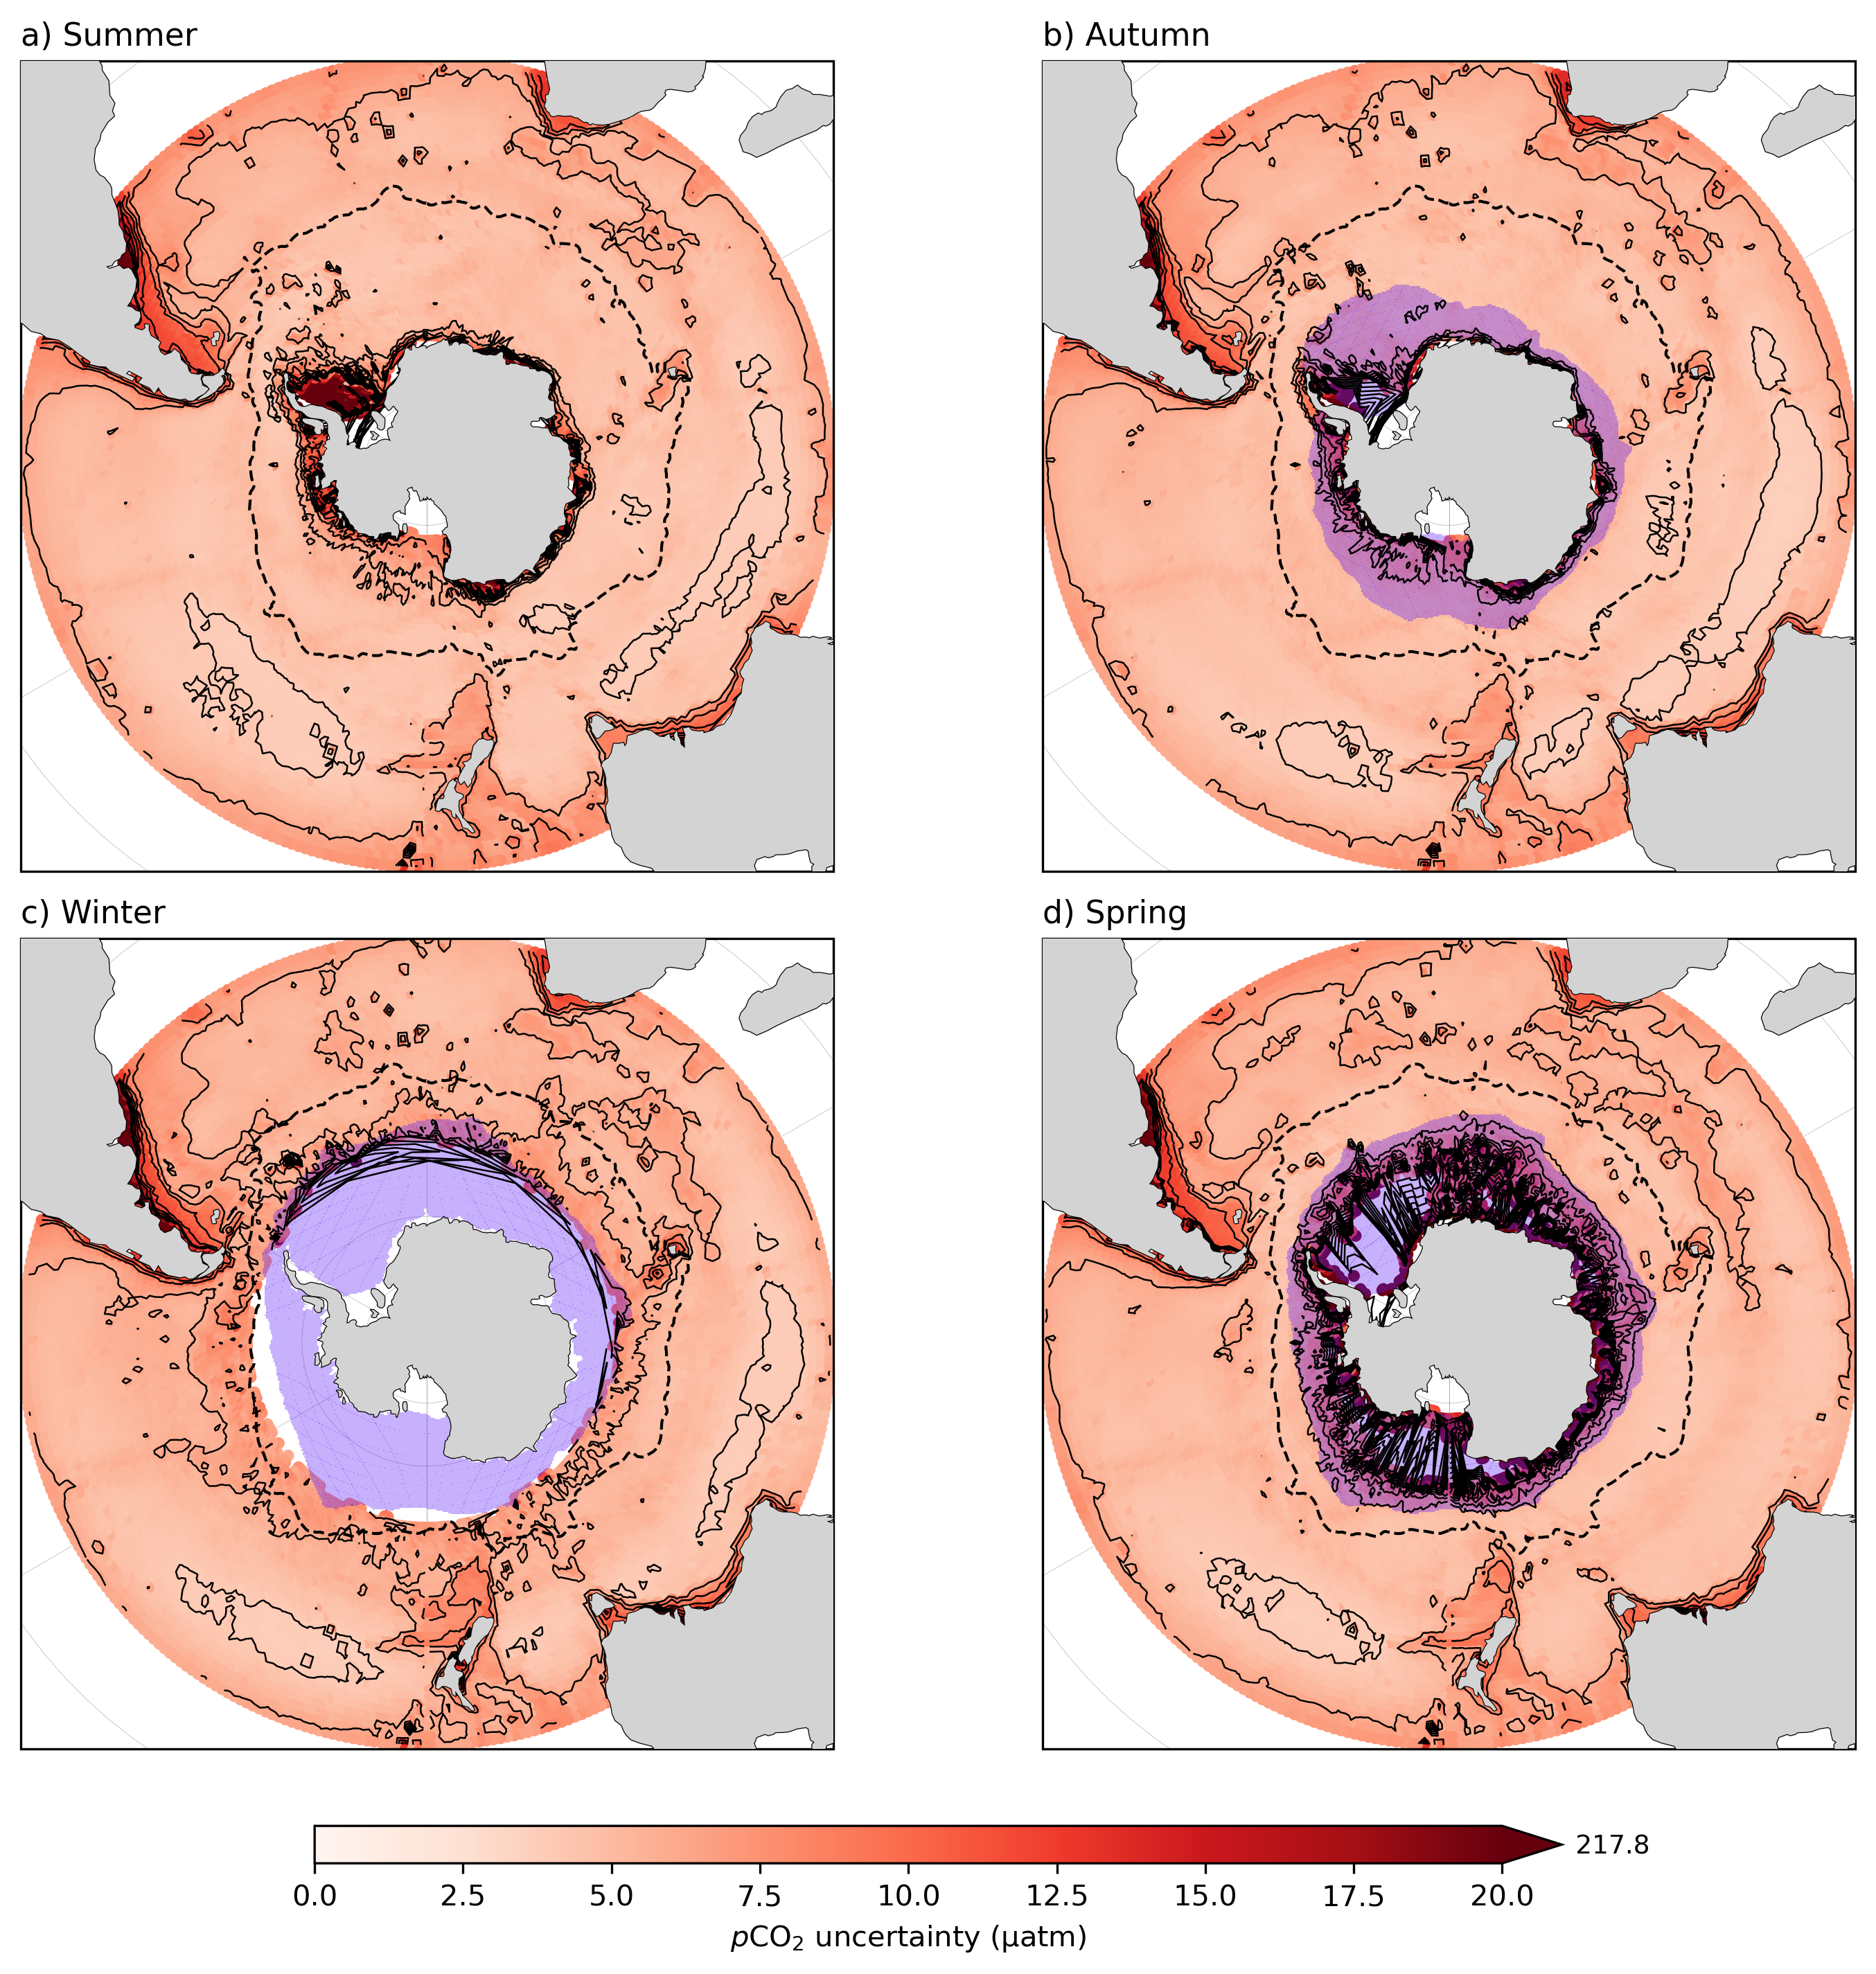

In [3]:
# ============================================================
# 6) PLOT FLOATS SEASONAL UNCERTAINTY
# ============================================================

plot_seasonal_uncertainty_maps(
    seasonal_floats,
    "FLOATS Predictions",
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/"
    "FLOATS_seasonal_MC_uncertainty_maps.png",
    contour_step=2,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,
    ice_alpha=0.35,
    fronts=fronts
)